# 13-1. 주요변수별 선정 모델의 첫 origin 예측구간

`12`시리즈에서 선정한 모델로 첫 채점 origin(origin 1)의 4분기 예측구간(90%)을 그린다. 남색 선은 훈련 데이터(예측 시점 전 8분기), 파란 선은 점예측, 음영은 90% 구간, 점선 7개는 7분위(0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9)로, 짝이 되는 분위수끼리 같은 색이다((0.1, 0.9) 보라, (0.2, 0.8) 초록, (0.3, 0.7) 하늘, 0.5 회색). 주황 선은 실제값으로, 구간 안이면 동그라미, 밖이면 X로 표시한다.

- **첫 채점 origin**: 훈련 구간 35개(변수별로 X3_l1, X2, X4는 11Q1~19Q3, X1와 X5는 11Q2~19Q4, X6은 10Q2~18Q4)
- **구간 만들기**: 자체 = 점예측 ± 1.645 x σ, 리샘플링 = 이 origin 이전에 정답이 확정된 오차를 다시 뽑아 만든 5%, 95% 분위수(12시리즈와 같은 방식, 같은 시드)
- **검증**: 12시리즈 캐시의 같은 조합과 적중 여부, 구간 폭이 일치하는지 확인한다.

## 1. 구현

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')
from dataclasses import dataclass
import numpy as np
import pandas as pd
import pmdarima as pm
from scipy import stats
from arch.univariate import ARX, ConstantMean, GARCH, ZeroMean
from scipy.optimize import minimize
XI_MEAN, XI_VAR, MAX_PHI = -1.2704, np.pi ** 2 / 2, 0.97
H, ALPHA, P_MAX = 4, 0.10, 3
Z = stats.norm.ppf(1 - ALPHA / 2)


@dataclass(frozen=True)
class Spec:
    d: int = 1
    D: int = 0
    m: int = 4
    seasonal_ar: bool = False        # True면 계절 AR 차수 P도 AR단독 auto_arima가 탐색(D > 0이면 항상 탐색)

    @property
    def const(self):
        return self.d + self.D == 0


# ---------------------------------------------------------------- 차분·역차분·σ 전파
def diff_poly(sp):
    c = np.array([1.0])
    for _ in range(sp.d):
        c = np.convolve(c, [1.0, -1.0])
    for _ in range(sp.D):
        c = np.convolve(c, np.r_[1.0, np.zeros(sp.m - 1), -1.0])
    return c


def difference(y, sp):
    c, y = diff_poly(sp), np.asarray(y, float)
    k = len(c) - 1
    return y.copy() if k == 0 else np.convolve(y, c)[k:len(y)]


def undiff(w_fc, y, sp):
    c = diff_poly(sp)
    hist, out = list(map(float, y)), []
    for wf in w_fc:
        yt = wf - sum(c[i] * hist[-i] for i in range(1, len(c)))
        hist.append(yt)
        out.append(yt)
    return np.array(out)


def level_sigma(lags, ar, sp, innov_var):
    """h단계 수준 예측오차의 표준편차. 평균식 AR 다항식과 차분 다항식을 곱한 다항식으로 충격반응(psi)을 구한다."""
    ar_poly = np.zeros(max(lags) + 1 if len(lags) else 1)
    ar_poly[0] = 1.0
    for l, a in zip(lags, ar):
        ar_poly[l] -= a
    a_full = -np.convolve(ar_poly, diff_poly(sp))[1:]
    psi = np.zeros(H)
    for j in range(H):
        psi[j] = 1.0 if j == 0 else sum(a_full[k - 1] * psi[j - k] for k in range(1, min(j, len(a_full)) + 1))
    return np.sqrt(np.array([sum(psi[h - i] ** 2 * innov_var[i] for i in range(h + 1)) for h in range(H)]))


def lag_list(p, P, m):
    return sorted(set(range(1, p + 1)) | {m * j for j in range(1, P + 1)})


# ---------------------------------------------------------------- 구조 선택 (AR단독 auto_arima)
def select_structure(train, sp):
    kw = dict(d=sp.d, start_q=0, max_q=0, max_p=P_MAX, information_criterion="aicc", with_intercept=sp.const,
              suppress_warnings=True, error_action="ignore")
    if sp.D or sp.seasonal_ar:
        m = pm.auto_arima(train, seasonal=True, m=sp.m, D=sp.D, start_Q=0, max_Q=0, **kw)
        return m.order[0], m.seasonal_order[0], m
    m = pm.auto_arima(train, seasonal=False, **kw)
    return m.order[0], 0, m


def ar_forecast(m):
    fc, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    return np.asarray(fc), (conf[:, 1] - conf[:, 0]) / (2 * Z)


# ---------------------------------------------------------------- GARCH 동시
def garch_forecast(train, sp, lags):
    w = difference(train, sp)
    if lags:
        am = ARX(w, lags=lags, constant=sp.const, rescale=False)
    else:
        am = ConstantMean(w, rescale=False) if sp.const else ZeroMean(w, rescale=False)
    am.volatility = GARCH(p=1, q=1)
    res = am.fit(disp="off")
    f = res.forecast(horizon=H, reindex=False)
    ar = [res.params[f"y[{l}]"] for l in lags]
    fc = undiff(f.mean.values[-1], train, sp)
    sig = level_sigma(lags, ar, sp, f.residual_variance.values[-1])
    if not (np.all(np.isfinite(fc)) and np.all(np.isfinite(sig))):
        raise ValueError("non-finite forecast")
    return fc, sig


# ---------------------------------------------------------------- SV 동시 (QML + 칼만필터)
def is_ar_stable(lags, ar):
    if not len(lags):
        return True
    mx = max(lags)
    a = np.zeros(mx)
    for l, c in zip(lags, ar):
        a[l - 1] = c
    comp = np.zeros((mx, mx))
    comp[0, :] = a
    if mx > 1:
        comp[1:, :-1] = np.eye(mx - 1)
    return np.max(np.abs(np.linalg.eigvals(comp))) < 0.999


def sv_residuals(w, lags, ar, c):
    mx = max(lags) if len(lags) else 0
    return np.array([w[t] - c - sum(a * w[t - l] for a, l in zip(ar, lags)) for t in range(mx, len(w))])


def sv_qml_negloglik(z_centered, phi, sigma_eta2):
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred, loglik = 0.0, P0, 0.0
    for z in z_centered:
        F = P_pred + XI_VAR
        v = z - h_pred
        loglik += -0.5 * (np.log(2 * np.pi * F) + v ** 2 / F)
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    return -loglik


def _unpack(params, k, const):
    ar = params[:k]
    c = params[k] if const else 0.0
    j = k + (1 if const else 0)
    return ar, c, MAX_PHI * np.tanh(params[j]), np.exp(params[j + 1]) ** 2


def joint_sv_negloglik(params, w, lags, const):
    ar, c, phi, s2 = _unpack(params, len(lags), const)
    if not is_ar_stable(lags, ar):
        return 1e10
    z = np.log(sv_residuals(w, lags, ar, c) ** 2 + 1e-8)
    return sv_qml_negloglik(z - z.mean(), phi, s2)


def sv_forecast(train, sp, lags):
    w = difference(train, sp)
    k = len(lags)
    x0 = [0.0] * k + ([float(np.mean(w))] if sp.const else []) + [1.5, np.log(0.3)]
    res = minimize(joint_sv_negloglik, x0, args=(w, lags, sp.const), method="Nelder-Mead", options={"maxiter": 3000})
    ar, c, phi, s2 = _unpack(res.x, k, sp.const)
    if not is_ar_stable(lags, ar) or res.fun >= 1e9:
        raise ValueError("SV fit failed")
    z = np.log(sv_residuals(w, lags, ar, c) ** 2 + 1e-8)
    zm = z.mean()
    P, h = s2 / (1 - phi ** 2), 0.0
    for x in z - zm:
        K = P / (P + XI_VAR)
        hf, Pf = h + K * (x - h), P * (1 - K)
        h, P = phi * hf, phi ** 2 * Pf + s2
    past = list(w[-max(lags):]) if k else []
    mean_w = []
    for _ in range(H):
        pred = c + sum(a * past[-l] for a, l in zip(ar, lags))
        mean_w.append(pred)
        past.append(pred)
    v = [np.exp(zm - XI_MEAN + phi ** j * hf + (phi ** (2 * j) * Pf + s2 * sum(phi ** (2 * i) for i in range(j))) / 2) for j in range(1, H + 1)]
    fc, sig = undiff(mean_w, train, sp), level_sigma(lags, ar, sp, v)
    if not (np.all(np.isfinite(fc)) and np.all(np.isfinite(sig))):
        raise ValueError("non-finite forecast")
    return fc, sig


# ---------------------------------------------------------------- 공용 진입점
def forecast(model, train, sp=Spec()):
    """model: 'AR단독' | 'GARCH' | 'SV'. 반환: (예측 4개, σ 4개, 사용한 모델, (p, P)). 적합 실패 시 NaN을 돌려준다(src='실패')."""
    p, P, m = select_structure(train, sp)
    if model == "AR단독":
        fc, sig = ar_forecast(m)
        return fc, sig, "AR단독", (p, P)
    lags = lag_list(p, P, sp.m)
    try:
        fc, sig = (garch_forecast if model == "GARCH" else sv_forecast)(train, sp, lags)
        return fc, sig, model, (p, P)
    except Exception:
        nan = np.full(H, np.nan)
        return nan, nan, "실패", (p, P)


## 2. 변수별 선정 모델과 계산

선정 모델은 `12`의 `12-13`에서 정한 조합이다. 모델에는 변수를 `100 / 표준편차`배 해서 넣고(X3_l1은 그대로), 결과는 원래 단위로 되돌려 그린다.

In [2]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
NAMES = {"X3_l1": "X3", "X6_l1": "X6", "X2": "X2",
         "X1_l1": "X1", "X5_l1": "X5", "X4": "X4"}
SEL = {"X3_l1": ("GARCH", 1, 0, "원", "리샘플링"), "X6_l1": ("SV", 1, 0, "원", "자체"), "X2": ("AR단독", 0, 0, "원", "자체"),
       "X1_l1": ("GARCH", 0, 0, "원", "리샘플링"), "X5_l1": ("GARCH", 0, 0, "로그", "자체"), "X4": ("GARCH", 0, 0, "원", "리샘플링")}
CACHE_NO = {"X3_l1": 15, "X6_l1": 7, "X2": 8, "X1_l1": 9, "X5_l1": 10, "X4": 11}
SCALE, N_ENS, MIN_TRAIN, INITIAL_CALIB = 100.0, 500, 20, 15
SEED = 42                                                                  # 리샘플링 난수 시드(모든 변수, 모델, (d, D)가 같은 시드를 써서 같은 난수로 비교한다)
TAUS = [0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9]                                  # 7분위
TAU_COLOR = {0.1: "#CC79A7", 0.9: "#CC79A7", 0.2: "#009E73", 0.8: "#009E73", 0.3: "#56B4E9", 0.7: "#56B4E9", 0.5: "#6B7280"}   # (0.1, 0.9) (0.2, 0.8) (0.3, 0.7) (0.5) 세트별 색


def first_origin_interval(v):
    model, d, D, sc, iv = SEL[v]
    sp, logm, std = Spec(d=d, D=D), sc == "로그", model != "AR단독"
    s_ = raw[["quarter", v]].dropna().reset_index(drop=True)
    y0, q = s_[v].values.astype(float), s_["quarter"].values
    vals = y0
    var_std = y0.std()                                                          # 점수 정규화 단위(원래 단위)

    def ser(o):                                                                 # origin o의 단위 상수(훈련 구간 표준편차 기준)와 모델 입력 계열
        C = 100 / vals[:o].std()
        return C, (SCALE * np.log(vals * C) if logm else vals * C)
    tf = (lambda x: np.exp(np.asarray(x) / SCALE)) if logm else (lambda x: np.asarray(x))
    o1 = MIN_TRAIN + INITIAL_CALIB                                        # 첫 채점 origin
    errs = {h: [] for h in range(1, H + 1)}
    for o in range(MIN_TRAIN, o1):                                        # 이전 origin의 예측 오차를 쌓는다
        C, series = ser(o)
        fc, sig, _, _ = forecast(model, series[:o], sp)
        for h in range(1, H + 1):
            e = series[o + h - 1] - fc[h - 1]
            errs[h].append((o, e / max(sig[h - 1], 1e-6) if std else e / (1 if logm else C)))
    C, series = ser(o1)
    fc, sig, src, (p, P) = forecast(model, series[:o1], sp)
    rng = np.random.default_rng(SEED)
    rows = []
    for h in range(1, H + 1):
        s_h = max(sig[h - 1], 1e-6)
        if iv == "자체":
            lo, hi = tf(fc[h - 1] - Z * s_h), tf(fc[h - 1] + Z * s_h)
            qs = tf(fc[h - 1] + s_h * stats.norm.ppf(TAUS))
        else:
            pool = np.array([e for o2, e in errs[h] if o2 + h <= o1]) * (C if (not std and not logm) else 1)      # 정답이 이미 확정된 오차만
            samples = fc[h - 1] + (s_h if std else 1.0) * rng.choice(pool - np.median(pool), size=N_ENS, replace=True)
            lo, hi = tf(np.quantile(samples, [ALPHA / 2, 1 - ALPHA / 2]))
            qs = tf(np.quantile(samples, TAUS))                                   # 같은 표본의 7분위(추가 난수 없음)
        lo, hi, qs = lo / C, hi / C, np.asarray(qs) / C                       # 원래 단위로 되돌린다
        a = vals[o1 + h - 1]
        rows.append({"분기": q[o1 + h - 1], "h": h, "점예측": float(tf(fc[h - 1])) / C, "하한": float(lo), "상한": float(hi), "실제": a,
                     "적중": bool(lo <= a <= hi), "폭_정규화": float((hi - lo) / var_std), "src": src,
                     **{f"q{int(round(tt * 100))}": float(qq) for tt, qq in zip(TAUS, qs)}})
    return pd.DataFrame(rows), dict(q=q, y=y0, o1=o1, p=p, P=P)


R = {v: first_origin_interval(v) for v in SEL}
for v, (t, info) in R.items():
    print(f"{v}: 훈련 {info['q'][0]}~{info['q'][info['o1'] - 1]}, 예측 {t['분기'].iloc[0]}~{t['분기'].iloc[-1]}, 적중 {int(t['적중'].sum())}/4, 사용 모델 {t['src'].iloc[0]}")

X3_l1: 훈련 2011Q1~2019Q3, 예측 2019Q4~2020Q3, 적중 1/4, 사용 모델 GARCH
X6_l1: 훈련 2010Q2~2018Q4, 예측 2019Q1~2019Q4, 적중 4/4, 사용 모델 SV
X2: 훈련 2011Q1~2019Q3, 예측 2019Q4~2020Q3, 적중 3/4, 사용 모델 AR단독
X1_l1: 훈련 2011Q2~2019Q4, 예측 2020Q1~2020Q4, 적중 3/4, 사용 모델 GARCH
X5_l1: 훈련 2011Q2~2019Q4, 예측 2020Q1~2020Q4, 적중 2/4, 사용 모델 GARCH
X4: 훈련 2011Q1~2019Q3, 예측 2019Q4~2020Q3, 적중 3/4, 사용 모델 GARCH


## 3. 12시리즈 결과와 일치하는지 확인

첫 채점 origin의 같은 조합이 캐시에 저장한 적중 여부와 구간 폭(정규화)과 같아야 한다.

In [3]:
rows = []
for v, (t, info) in R.items():
    model, d, D, sc, iv = SEL[v]
    c = pd.read_pickle(f"../cache/cache_12{CACHE_NO[v]}_{v}_df.pkl" if v != "X3_l1" else "../cache/cache_1215_X3_l1_df.pkl")
    c = c[(c["모델"] == model) & (c["d"] == d) & (c["D"] == D) & (c["스케일"] == sc) & (c["구간"] == iv) & (c["origin"] == info["o1"])].sort_values("h")
    rows.append({"변수": v, "적중 일치": bool((c["적중"].values == (t["적중"].values * 100)).all()), "폭 최대 차이": float(np.abs(c["폭"].values - t["폭_정규화"].values).max())})
display(pd.DataFrame(rows).set_index("변수"))

,적중 일치,폭 최대 차이
변수,,
X3_l1,True,0.0
X6_l1,True,0.0
X2,True,0.0
X1_l1,True,0.0
X5_l1,True,0.0
X4,True,0.0


## 4. 예측구간 그래프 (origin 1)

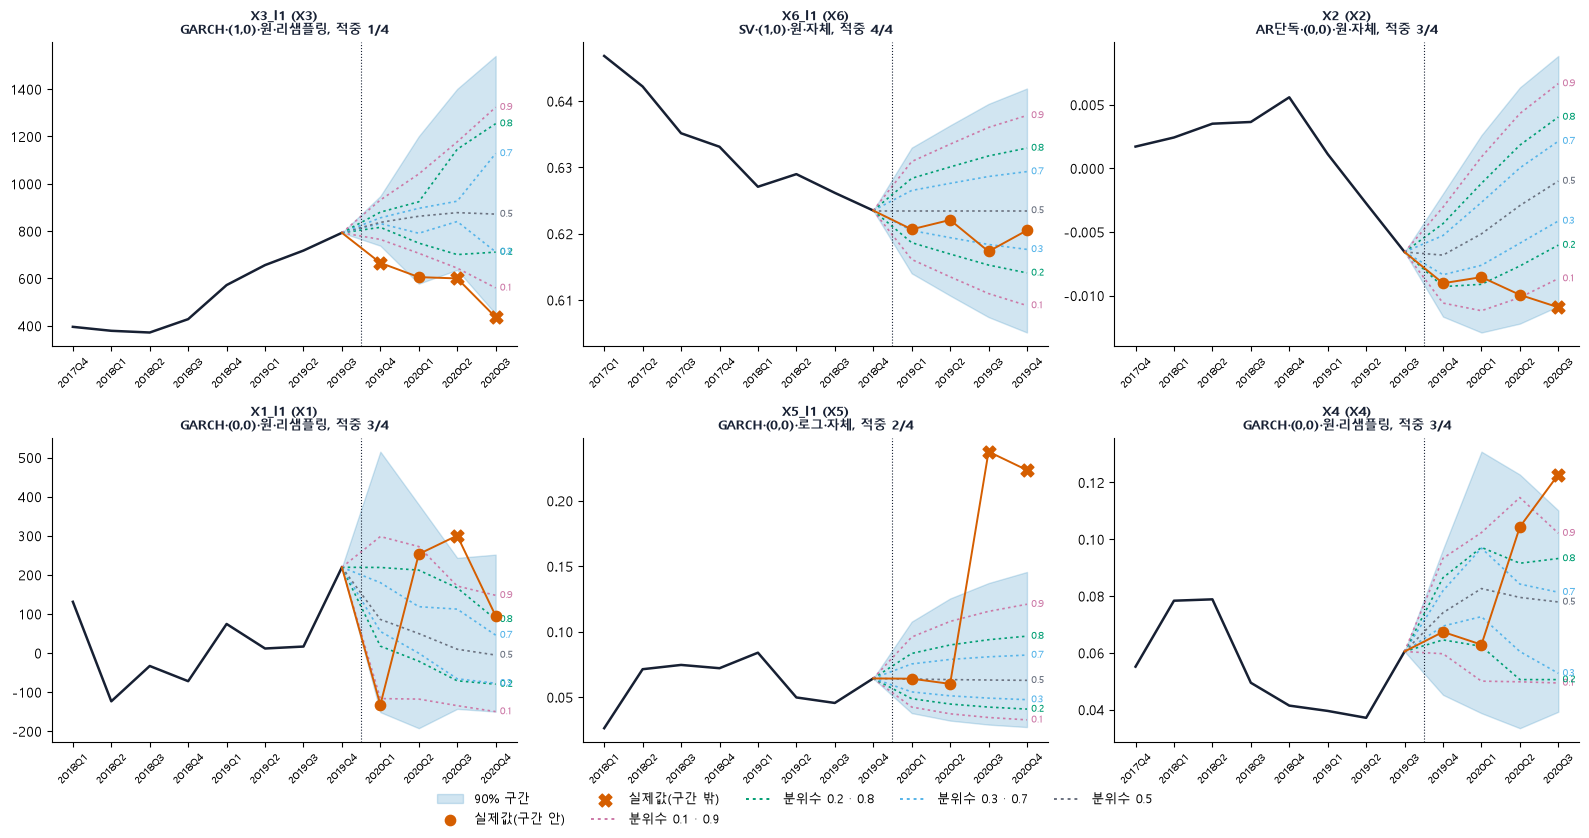

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.4))
for ax, (v, (t, info)) in zip(axes.ravel(), R.items()):
    q, y, o1 = info["q"], info["y"], info["o1"]
    k0 = max(0, o1 - 8)                                                       # 예측 시점 전 8분기만 표시
    k = np.arange(k0, o1 + 4)
    ax.plot(k[:o1 - k0], y[k0:o1], color="#172033", linewidth=1.8)                                      # 훈련 데이터(최근 8분기)
    fk = np.arange(o1, o1 + 4)
    xs, last = np.r_[o1 - 1, fk], y[o1 - 1]                                                          # 구간은 마지막 훈련 값에서 시작해 벌어진다
    ax.fill_between(xs, np.r_[last, t["하한"].values], np.r_[last, t["상한"].values], color="#0072B2", alpha=0.18, label="90% 구간")
    for tt in TAUS:                                                                                  # 7분위 점선(짝이 되는 분위수끼리 같은 색)
        col = TAU_COLOR[tt]
        ax.plot(xs, np.r_[last, t[f"q{int(round(tt * 100))}"].values], color=col, linewidth=1.2, linestyle=(0, (1.5, 2)))
        ax.text(fk[-1] + 0.12, t[f"q{int(round(tt * 100))}"].values[-1], f"{tt:g}", fontsize=6.5, color=col, va="center")
    ax.plot(np.r_[o1 - 1, fk], np.r_[y[o1 - 1], t["실제"].values], color="#D55E00", linewidth=1.4, zorder=4)   # 실제값을 선으로 이음
    hit = t["적중"].values
    ax.scatter(fk[hit], t["실제"].values[hit], color="#D55E00", s=55, zorder=5, label="실제값(구간 안)")
    ax.scatter(fk[~hit], t["실제"].values[~hit], color="#D55E00", marker="X", s=85, zorder=5, label="실제값(구간 밖)")
    ax.axvline(o1 - 0.5, color="#172033", linestyle=":", linewidth=0.8)
    ax.set_xticks(k)
    ax.set_xticklabels(q[k], rotation=45, fontsize=7.5)
    m, d, D, sc, iv = SEL[v]
    ax.set_title(f"{v} ({NAMES[v]})\n{m}·({d},{D})·{sc}·{iv}, 적중 {int(t['적중'].sum())}/4", fontsize=9.5, fontweight="bold", color="#172033")
    for sp_ in ("top", "right"):
        ax.spines[sp_].set_visible(False)
from matplotlib.lines import Line2D
h_, l_ = axes[0][0].get_legend_handles_labels()
for lab_, col_ in [("0.1 · 0.9", "#CC79A7"), ("0.2 · 0.8", "#009E73"), ("0.3 · 0.7", "#56B4E9"), ("0.5", "#6B7280")]:
    h_.append(Line2D([0], [0], color=col_, linewidth=1.4, linestyle=(0, (1.5, 2))))
    l_.append(f"분위수 {lab_}")
fig.legend(h_, l_, loc="lower center", ncol=5, frameon=False, fontsize=9.5)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

### 구간 색칠 버전

점선 대신 짝이 되는 분위수 사이를 색칠한다. 가장 바깥은 90% 구간(5~95%)이고, 안쪽으로 (0.1, 0.9) 보라, (0.2, 0.8) 초록, (0.3, 0.7) 하늘이다. 0.5는 점선 하나다.

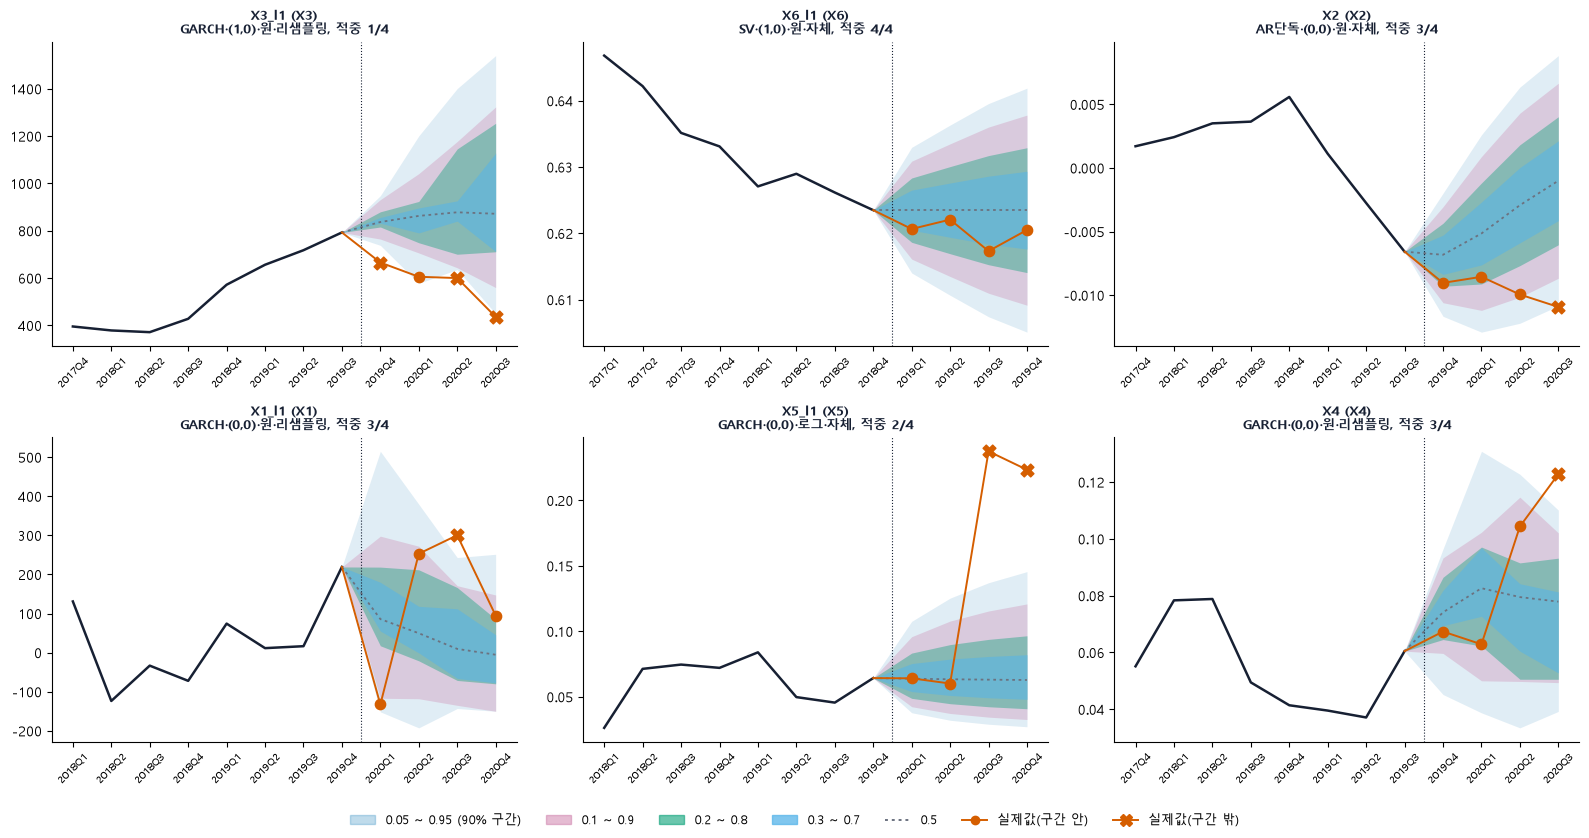

In [5]:
BANDS = [(0.1, 0.9, "#CC79A7", 0.30), (0.2, 0.8, "#009E73", 0.38), (0.3, 0.7, "#56B4E9", 0.55)]           # (아래, 위, 색, 투명도) 바깥 구간부터
fig, axes = plt.subplots(2, 3, figsize=(16, 8.4))
for ax, (v, (t, info)) in zip(axes.ravel(), R.items()):
    q, y, o1 = info["q"], info["y"], info["o1"]
    k0 = max(0, o1 - 8)
    k = np.arange(k0, o1 + 4)
    ax.plot(k[:o1 - k0], y[k0:o1], color="#172033", linewidth=1.8)
    fk = np.arange(o1, o1 + 4)
    xs, last = np.r_[o1 - 1, fk], y[o1 - 1]
    ax.fill_between(xs, np.r_[last, t["하한"].values], np.r_[last, t["상한"].values], color="#0072B2", alpha=0.12, linewidth=0)   # 가장 바깥: 90% 구간(5~95%)
    for a_, b_, col, al in BANDS:
        ax.fill_between(xs, np.r_[last, t[f"q{int(round(a_ * 100))}"].values], np.r_[last, t[f"q{int(round(b_ * 100))}"].values], color=col, alpha=al, linewidth=0)
    ax.plot(xs, np.r_[last, t["q50"].values], color="#6B7280", linewidth=1.3, linestyle=(0, (1.5, 2)))              # 0.5는 점선
    ax.plot(np.r_[o1 - 1, fk], np.r_[y[o1 - 1], t["실제"].values], color="#D55E00", linewidth=1.4, zorder=4)
    hit = t["적중"].values
    ax.scatter(fk[hit], t["실제"].values[hit], color="#D55E00", s=55, zorder=5)
    ax.scatter(fk[~hit], t["실제"].values[~hit], color="#D55E00", marker="X", s=85, zorder=5)
    ax.axvline(o1 - 0.5, color="#172033", linestyle=":", linewidth=0.8)
    ax.set_xticks(k)
    ax.set_xticklabels(q[k], rotation=45, fontsize=7.5)
    m, d, D, sc, iv = SEL[v]
    ax.set_title(f"{v} ({NAMES[v]})\n{m}·({d},{D})·{sc}·{iv}, 적중 {int(t['적중'].sum())}/4", fontsize=9.5, fontweight="bold", color="#172033")
    for sp_ in ("top", "right"):
        ax.spines[sp_].set_visible(False)
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
h_ = [Patch(color="#0072B2", alpha=0.25, label="0.05 ~ 0.95 (90% 구간)")] + [Patch(color=col, alpha=min(al + 0.2, 1), label=f"{a_:g} ~ {b_:g}") for a_, b_, col, al in BANDS]
h_ += [Line2D([0], [0], color="#6B7280", linewidth=1.4, linestyle=(0, (1.5, 2)), label="0.5"),        Line2D([0], [0], color="#D55E00", marker="o", linewidth=1.4, label="실제값(구간 안)"), Line2D([0], [0], color="#D55E00", marker="X", markersize=9, linewidth=1.4, label="실제값(구간 밖)")]
fig.legend(handles=h_, loc="lower center", ncol=7, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

### 변수 하나만 보기

한 변수를 골라 두 가지 표현(점선, 색칠)을 나란히 크게 그린다. `PICK`만 바꾸면 다른 변수도 볼 수 있다.

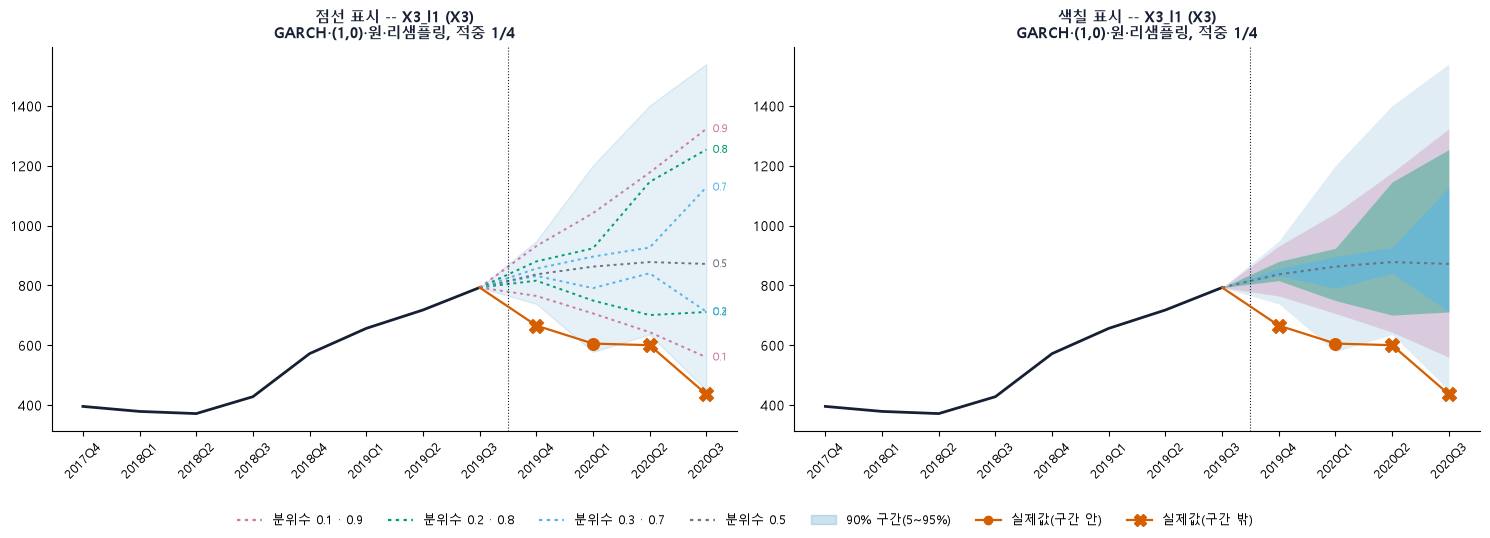

In [6]:
PICK = "X3_l1"                                                                            # 보고 싶은 변수


def draw_one(ax, v, style):
    t, info = R[v]
    q, y, o1 = info["q"], info["y"], info["o1"]
    k0 = max(0, o1 - 8)
    k = np.arange(k0, o1 + 4)
    fk = np.arange(o1, o1 + 4)
    xs, last = np.r_[o1 - 1, fk], y[o1 - 1]
    ax.plot(k[:o1 - k0], y[k0:o1], color="#172033", linewidth=2)
    if style == "점선":
        ax.fill_between(xs, np.r_[last, t["하한"].values], np.r_[last, t["상한"].values], color="#0072B2", alpha=0.10)
        for tt in TAUS:
            col = TAU_COLOR[tt]
            ax.plot(xs, np.r_[last, t[f"q{int(round(tt * 100))}"].values], color=col, linewidth=1.4, linestyle=(0, (1.5, 2)))
            ax.text(fk[-1] + 0.12, t[f"q{int(round(tt * 100))}"].values[-1], f"{tt:g}", fontsize=8, color=col, va="center")
    else:
        ax.fill_between(xs, np.r_[last, t["하한"].values], np.r_[last, t["상한"].values], color="#0072B2", alpha=0.12, linewidth=0)   # 가장 바깥: 90% 구간(5~95%)
        for a_, b_, col, al in BANDS:
            ax.fill_between(xs, np.r_[last, t[f"q{int(round(a_ * 100))}"].values], np.r_[last, t[f"q{int(round(b_ * 100))}"].values], color=col, alpha=al, linewidth=0)
        ax.plot(xs, np.r_[last, t["q50"].values], color="#6B7280", linewidth=1.5, linestyle=(0, (1.5, 2)))
    ax.plot(np.r_[o1 - 1, fk], np.r_[last, t["실제"].values], color="#D55E00", linewidth=1.6, zorder=4)
    hit = t["적중"].values
    ax.scatter(fk[hit], t["실제"].values[hit], color="#D55E00", s=70, zorder=5)
    ax.scatter(fk[~hit], t["실제"].values[~hit], color="#D55E00", marker="X", s=100, zorder=5)
    ax.axvline(o1 - 0.5, color="#172033", linestyle=":", linewidth=0.8)
    ax.set_xticks(k)
    ax.set_xticklabels(q[k], rotation=45, fontsize=9)
    m, d, D, sc, iv = SEL[v]
    ax.set_title(f"{style} 표시 -- {v} ({NAMES[v]})\n{m}·({d},{D})·{sc}·{iv}, 적중 {int(hit.sum())}/4", fontsize=10.5, fontweight="bold", color="#172033")
    for sp_ in ("top", "right"):
        ax.spines[sp_].set_visible(False)


fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
draw_one(axes[0], PICK, "점선")
draw_one(axes[1], PICK, "색칠")
h_ = [Line2D([0], [0], color=col, linewidth=1.6, linestyle=(0, (1.5, 2)), label=f"분위수 {lab_}") for lab_, col in [("0.1 · 0.9", "#CC79A7"), ("0.2 · 0.8", "#009E73"), ("0.3 · 0.7", "#56B4E9"), ("0.5", "#6B7280")]]
h_ += [Patch(color="#0072B2", alpha=0.2, label="90% 구간(5~95%)"), Line2D([0], [0], color="#D55E00", marker="o", linewidth=1.6, label="실제값(구간 안)"),
       Line2D([0], [0], color="#D55E00", marker="X", markersize=9, linewidth=1.6, label="실제값(구간 밖)")]
fig.legend(handles=h_, loc="lower center", ncol=7, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()


### 변수 하나, 점선 버전 (최종)

점선 표시를 한 변수만 크게 그린다. 제목은 변수명(한글 변수명), 선정 모델, 예측 시점이다.

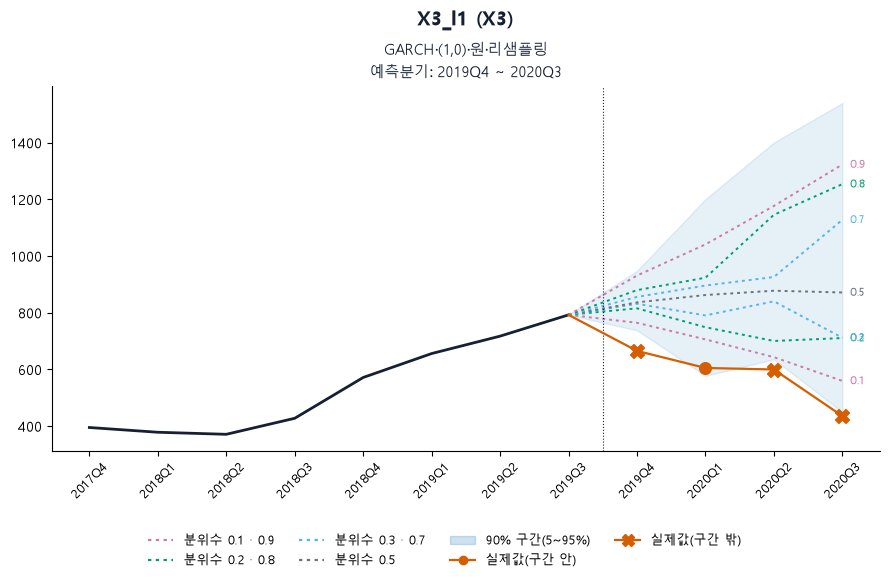

In [7]:
v = PICK
t, info = R[v]
q, o1 = info["q"], info["o1"]
m, d, D, sc, iv = SEL[v]
fig, ax = plt.subplots(figsize=(9, 5.8))
draw_one(ax, v, "점선")
ax.set_title(f"{v} ({NAMES[v]})", fontsize=14.5, fontweight="bold", color="#172033", pad=44)                        # 변수명을 크게
ax.text(0.5, 1.012, f"{m}·({d},{D})·{sc}·{iv}\n예측분기: {q[o1]} ~ {q[o1 + 3]}", transform=ax.transAxes, ha="center", va="bottom", fontsize=10.5, color="#172033", linespacing=1.5)   # 둘째, 셋째 줄은 작게
h_ = [Line2D([0], [0], color=col, linewidth=1.6, linestyle=(0, (1.5, 2)), label=f"분위수 {lab_}") for lab_, col in [("0.1 · 0.9", "#CC79A7"), ("0.2 · 0.8", "#009E73"), ("0.3 · 0.7", "#56B4E9"), ("0.5", "#6B7280")]]
h_ += [Patch(color="#0072B2", alpha=0.2, label="90% 구간(5~95%)"), Line2D([0], [0], color="#D55E00", marker="o", linewidth=1.6, label="실제값(구간 안)"),
       Line2D([0], [0], color="#D55E00", marker="X", markersize=9, linewidth=1.6, label="실제값(구간 밖)")]
fig.legend(handles=h_, loc="lower center", ncol=4, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()


## 5. 예측값과 구간 표

In [8]:
tab = pd.concat({v: t[["분기", "h", "점예측", "하한", "상한", "실제", "적중"]].set_index("분기") for v, (t, _) in R.items()})
with pd.option_context("display.float_format", "{:,.4g}".format, "display.width", 200):
    display(tab)

h       점예측       하한        상한        실제     적중
      분기                                                     
X3_l1 2019Q4  1     836.8    738.1       948     665.6  False
      2020Q1  2     862.7    577.6     1,201     605.4   True
      2020Q2  3     877.9    635.9     1,401     599.9  False
      2020Q3  4     886.9    449.4     1,540     435.9  False
X6_l1 2019Q1  1    0.6235    0.614     0.633    0.6207   True
      2019Q2  2    0.6235   0.6107    0.6363    0.6221   True
      2019Q3  3    0.6235   0.6074    0.6396    0.6173   True
      2019Q4  4    0.6235   0.6051    0.6419    0.6205   True
X2    2019Q4  1 -0.006826 -0.01166 -0.001989 -0.009035   True
      2020Q1  2 -0.005152 -0.01291  0.002603 -0.008555   True
      2020Q2  3 -0.002929 -0.01221  0.006353 -0.009948   True
      2020Q3  4 -0.001007 -0.01084  0.008829  -0.01093  False
X1_l1 2020Q1  1     85.84   -151.5       515    -132.5   True
      2020Q2  2     31.61   -192.4     379.6       253   True
      2020Q3  3     9.565     -143     243.3     300.3  False
      2020Q4  4    0.6015     -150     251.6     94.92   True
X5_l1 2020Q1  1   0.06376  0.03778    0.1076   0.06407   True
      2020Q2  2   0.06336  0.03203    0.1253    0.0601   True
      2020Q3  3   0.06305  0.02899    0.1371    0.2375  False
      2020Q4  4   0.06279  0.02709    0.1456    0.2234  False
X4    2019Q4  1   0.07389   0.0452   0.09643   0.06736   True
      2020Q1  2   0.07931  0.03874    0.1308   0.06287   True
      2020Q2  3    0.0795  0.03346    0.1227    0.1043   True
      2020Q3  4   0.07701  0.03923    0.1101    0.1228  False